# Experiment 2 — improved MAGMa intensity-only model

Learn **intensity only** from ordinary MS2 spectra with known precursors. MAGMa supplies candidate structures at observed peak locations; each peak receives the **maximum** score among its alternative fragments. Candidate identities remain latent, and the training objective remains spectrum cosine loss.

This revision fixes repeated assignments to nearby centroids, gives collision energy an explicit role in fragment scoring, and expands training to 1,050 fresh molecules. The MLP has **7,139 parameters**, with a small regularized fingerprint branch and a fragment-specific collision-energy head. A descriptor-only model and the frozen original model provide controls.

Experimental intensities are labels only. No MS3 observations, Glacier predictions, ionic-state enumeration, GNN, or new training framework are used. Select this repository's `.venv/bin/python` notebook kernel; reusable candidate and plotting code lives in `magma_workflow/`.


In [1]:
from pathlib import Path
import json
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "intensity_model_v2.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import torch
from IPython.display import display, Markdown, Image
from magma_workflow.dataset import Spectrum
from magma_workflow.candidates import get_candidate_bags
from intensity_model_v2 import load_model, predict_spectrum
from train_intensity_v2 import run_experiment, metrics_markdown
from train_intensity import plot_comparison

torch.set_num_threads(2)
DATA = ROOT / "msnlib" / "20241003_enamdisc_pos_msn.json"
OUTPUT = ROOT / "results" / "experiment_2_v2"


## Small, auditable changes

- Sample **1,500 fresh precursor molecules** with up to three distinct collision energies each, using seed `20260923`. Split 70% / 15% / 15%: **1,050 training, 225 validation, 225 test** groups.
- Exclude all original 300 molecules and equivalent InChI connectivity identities. Canonical non-stereochemical SMILES and an InChI connectivity guard keep stereoisomers and equivalent molecular identities from crossing splits.
- Retain the original input restrictions: `SINGLE_BEST_SCAN` MS2, scalar nonnegative collision energy, charge +1, `[M+H]+` or `[M]+`, and connected non-isotopic precursors with at most 35 heavy atoms.
- Assign each exact heavy-graph/formula/charge identity to its **nearest already-matched centroid**, using mass alone. Ties prefer lower m/z, then earlier input order. Assignment occurs separately within each scan after shared MAGMa generation. Empty bags remain on the output axis with zero intensity.
- Use **277 features**: precursor and fragment fingerprints folded to 128 bits each, 20 structural/mass-error descriptors, and collision energy. Fragment graphs need no local ionic-state assignment or valence repair.
- A downweighted 16-unit fingerprint projection uses dropout `0.15`. A 48 → 24 → 3 MLP predicts fragment-specific coefficients `a, b, c`; candidate intensity is `Softplus(a + b E + c E²)`, with `E = (CE - 40) / 20`.
- Train with AdamW, weight decay `0.01`, latent **max** aggregation, and full-spectrum cosine loss. Validation alone chooses the checkpoint. The descriptor-only baseline uses the same CE head without fingerprints.

Implementation: [`intensity_model_v2.py`](intensity_model_v2.py), [`intensity_data_v2.py`](intensity_data_v2.py), [`train_intensity_v2.py`](train_intensity_v2.py).


In [2]:
# Run All loads saved metrics by default; it does not load the full library or feature cache.
# If results are absent, or RETRAIN=True, prepare the bounded sample and train both small models.
RETRAIN = False
if RETRAIN or not (OUTPUT / "metrics.json").is_file():
    results = run_experiment(DATA, OUTPUT, molecules=1500, seed=20260923,
                             workers=2, epochs=100, patience=15)
else:
    results = json.loads((OUTPUT / "metrics.json").read_text())

print("Molecules:", results["molecule_counts"])
print("Spectra:", results["spectrum_counts"])
print("Parameter counts:", results["parameter_counts"])
print("Validation-selected epochs:", results["best_epochs"])


Molecules: {'train': 1050, 'validation': 225, 'test': 225}
Spectra: {'train': 3133, 'validation': 672, 'test': 668}
Parameter counts: {'energy_mlp': 7139, 'descriptor_only': 2259}
Validation-selected epochs: {'energy_mlp': 5, 'descriptor_only': 88}


## Fresh held-out evaluation

Every model below is evaluated on the **same fresh validation or test spectra**. The original model's earlier test cohort is separate, so compare models within these tables rather than comparing across cohorts. Test evaluation happens after all training and checkpoint selection.

Cosine uses **all observed experimental peak locations**, including zeros at unsupported locations. Spectra receive equal weight; completely unsupported predictions receive cosine zero. Thresholds mean strictly greater than `0.5` or `0.7`.

- `energy_mlp`: small CE-conditioned fingerprint model with nearest assignment.
- `descriptor_only`: the same conditioning with the fingerprint branch removed.
- `old_original_support`: the frozen original checkpoint with its original matching.
- `old_nearest_support`: the frozen original checkpoint with corrected nearest matching.
- `equal_nearest_support` / `equal_original_support`: equal intensity at each supported peak, independently of candidate count.

**Effective peak count** is `(sum I)² / sum(I²)`; larger values indicate more diffuse intensity. **Strongest-peak accuracy** gives fractional credit among exactly tied predicted maxima, equivalent to uniformly breaking ties. An all-zero prediction gets zero credit. Normalized MAE remains available in `metrics.json`.


In [3]:
for split in ("validation", "test"):
    display(Markdown(f"### {split.title()}"))
    display(Markdown(metrics_markdown(results["metrics"][split])))
    experimental_count = results["metrics"][split]["energy_mlp"]["experimental_effective_peak_count"]
    print(f"Experimental effective peak count: {experimental_count:.2f}")
print("Strongest-peak accuracy uses fractional credit for tied predicted maxima.")


### Validation

| Model / support | Mean cosine | Median | >0.5 | >0.7 | Effective peaks | Strongest peak |
|---|---:|---:|---:|---:|---:|---:|
| energy_mlp | 0.5811 | 0.5671 | 61.3% | 31.4% | 12.63 | 31.4% |
| descriptor_only | 0.5971 | 0.5879 | 66.1% | 31.4% | 13.20 | 33.6% |
| old_original_support | 0.5177 | 0.5083 | 51.3% | 13.8% | 19.10 | 21.6% |
| old_nearest_support | 0.5199 | 0.5119 | 52.1% | 13.8% | 18.62 | 21.6% |
| equal_nearest_support | 0.4631 | 0.4461 | 36.0% | 7.9% | 22.41 | 9.2% |
| equal_original_support | 0.4583 | 0.4403 | 34.5% | 7.7% | 23.01 | 9.0% |

Experimental effective peak count: 4.76


### Test

| Model / support | Mean cosine | Median | >0.5 | >0.7 | Effective peaks | Strongest peak |
|---|---:|---:|---:|---:|---:|---:|
| energy_mlp | 0.5871 | 0.5813 | 62.1% | 31.1% | 12.48 | 30.7% |
| descriptor_only | 0.5961 | 0.5996 | 65.7% | 31.6% | 12.62 | 31.7% |
| old_original_support | 0.5092 | 0.5009 | 50.3% | 12.1% | 18.22 | 19.2% |
| old_nearest_support | 0.5108 | 0.5016 | 50.7% | 12.1% | 17.76 | 19.2% |
| equal_nearest_support | 0.4594 | 0.4414 | 34.1% | 8.4% | 21.26 | 9.1% |
| equal_original_support | 0.4556 | 0.4380 | 33.2% | 7.9% | 21.84 | 8.9% |

Experimental effective peak count: 4.54
Strongest-peak accuracy uses fractional credit for tied predicted maxima.


In [4]:
manifest = json.loads((OUTPUT / "manifest.json").read_text())
groups = {name: set(values) for name, values in manifest["splits"].items()}
connectivity = {name: set(values) for name, values in manifest["split_connectivity_keys"].items()}
for identities in (groups, connectivity):
    assert len(set.union(*identities.values())) == sum(map(len, identities.values()))
assert not set.union(*groups.values()).intersection(manifest["excluded_original_groups"])
assert not set.union(*connectivity.values()).intersection(manifest["excluded_original_connectivity_keys"])
print("Train/validation/test are molecule-disjoint, with no original-cohort overlap.")
print("Preparation audit:", manifest["counts"])
print("Recorded failures:", len(manifest["errors"]))


Train/validation/test are molecule-disjoint, with no original-cohort overlap.
Preparation audit: {'selected_molecules': 1500, 'selected_spectra': 4473, 'examples': 4473, 'molecules_by_split': {'train': 1050, 'validation': 225, 'test': 225}, 'by_split': {'test': 668, 'train': 3133, 'validation': 672}, 'unsupported_spectra': 1, 'errors': 0, 'candidate_rows': 521259}
Recorded failures: 0


## Does collision energy change predictions?

For each spectrum, keep candidate structures and the peak axis fixed and change only CE20 → CE60. Recompute the head's energy interactions and independently base-peak normalize the two predictions. Zero- and single-supported-peak cases are excluded because their normalized shape cannot change.

A lower prediction-to-prediction cosine and a larger mean absolute intensity change indicate stronger energy response. They do not establish that the change matches experimental chemistry.


| Model / support | CE20/60 prediction cosine | Mean absolute change (percentage points) | Eligible spectra |
|---|---:|---:|---:|
| energy_mlp | 0.889738 | 12.556 | 667 |
| descriptor_only | 0.776487 | 15.503 | 667 |
| old_original_support | 0.999999 | 0.075 | 667 |
| old_nearest_support | 0.999999 | 0.073 | 667 |
| equal_nearest_support | 1.000000 | 0.000 | 667 |

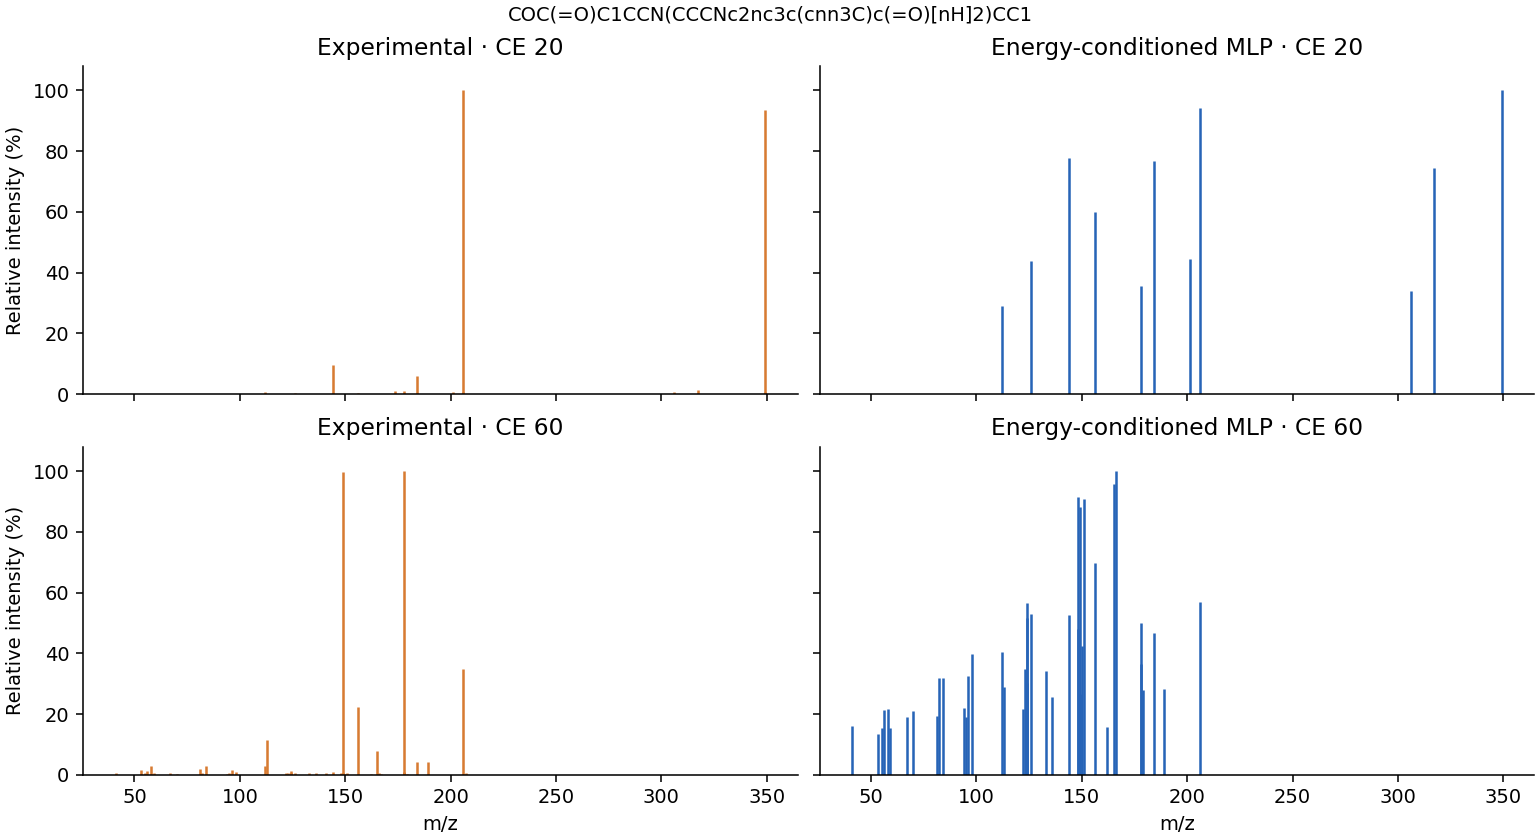

In [5]:
lines = ["| Model / support | CE20/60 prediction cosine | Mean absolute change (percentage points) | Eligible spectra |",
         "|---|---:|---:|---:|"]
for name, response in results["ce_response"]["test"].items():
    cosine = response["mean_prediction_cosine"]
    change = response["mean_absolute_normalized_intensity_change"]
    count = response["spectra_with_at_least_two_supported_peaks"]
    cosine_text = "n/a" if cosine is None else f"{cosine:.6f}"
    change_text = "n/a" if change is None else f"{100 * change:.3f}"
    lines.append(f"| {name} | {cosine_text} | {change_text} | {count} |")
display(Markdown("\n".join(lines)))

if results.get("energy_plot"):
    display(Image(filename=str(OUTPUT / results["energy_plot"])))


## Experimental versus predicted spectra

The first three distinct test molecules are shown, selected without inspecting scores. Predictions appear above zero and experimental intensities below on the same m/z axis. Each image also shows the equal-intensity baseline for that same spectrum.


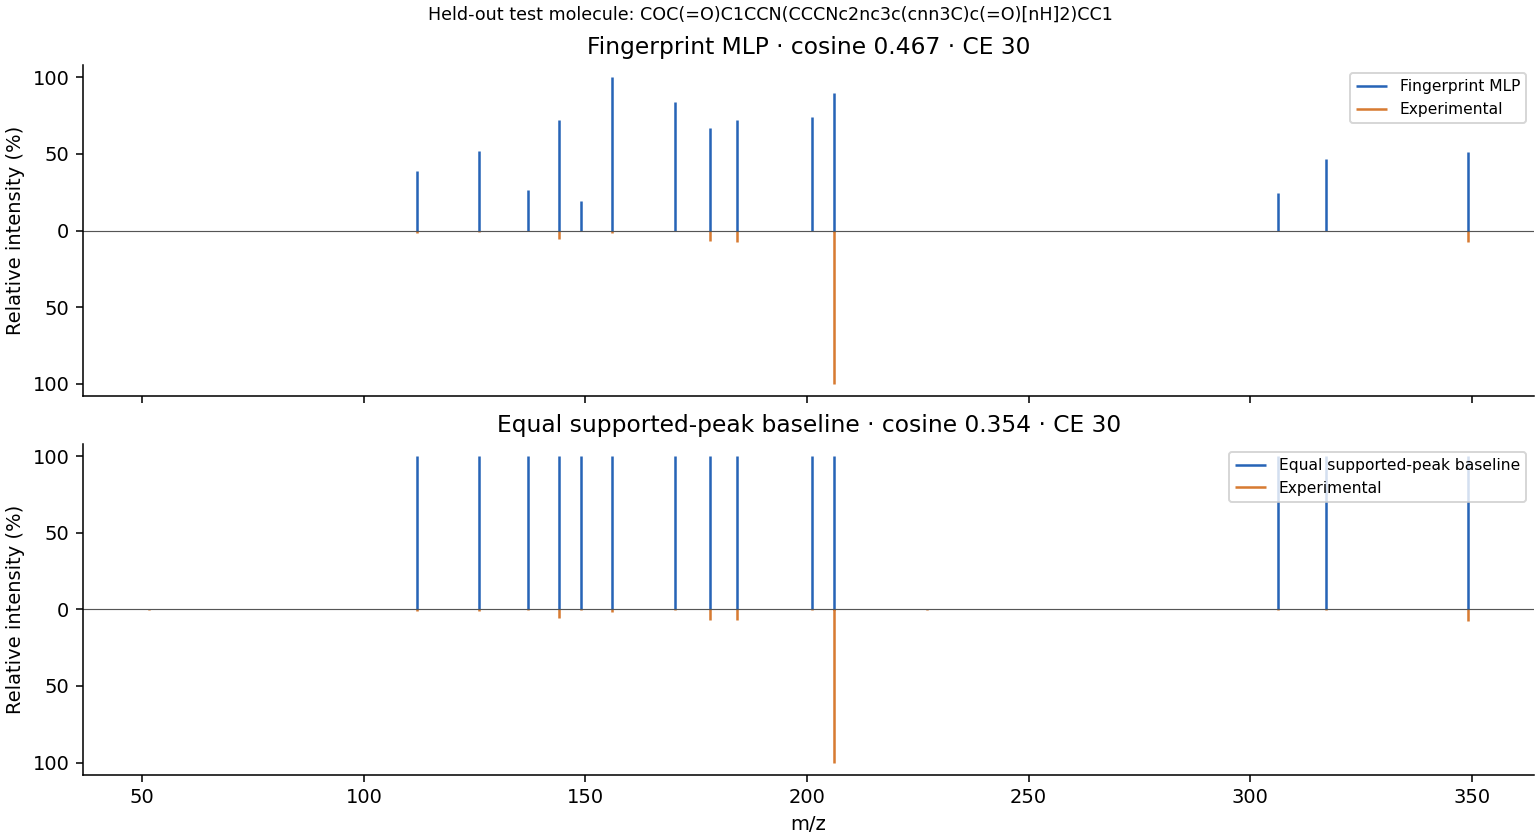

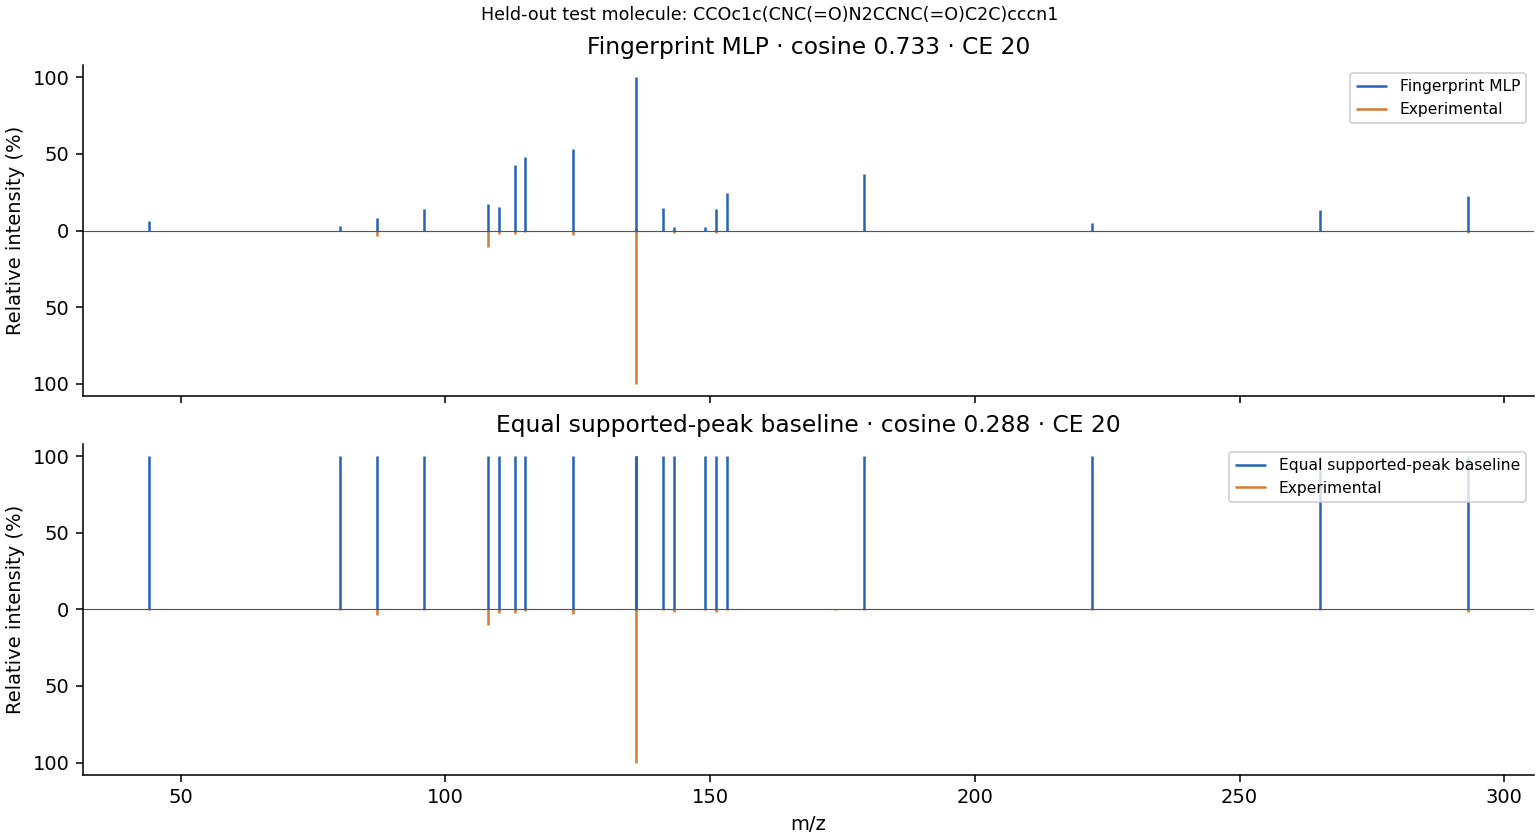

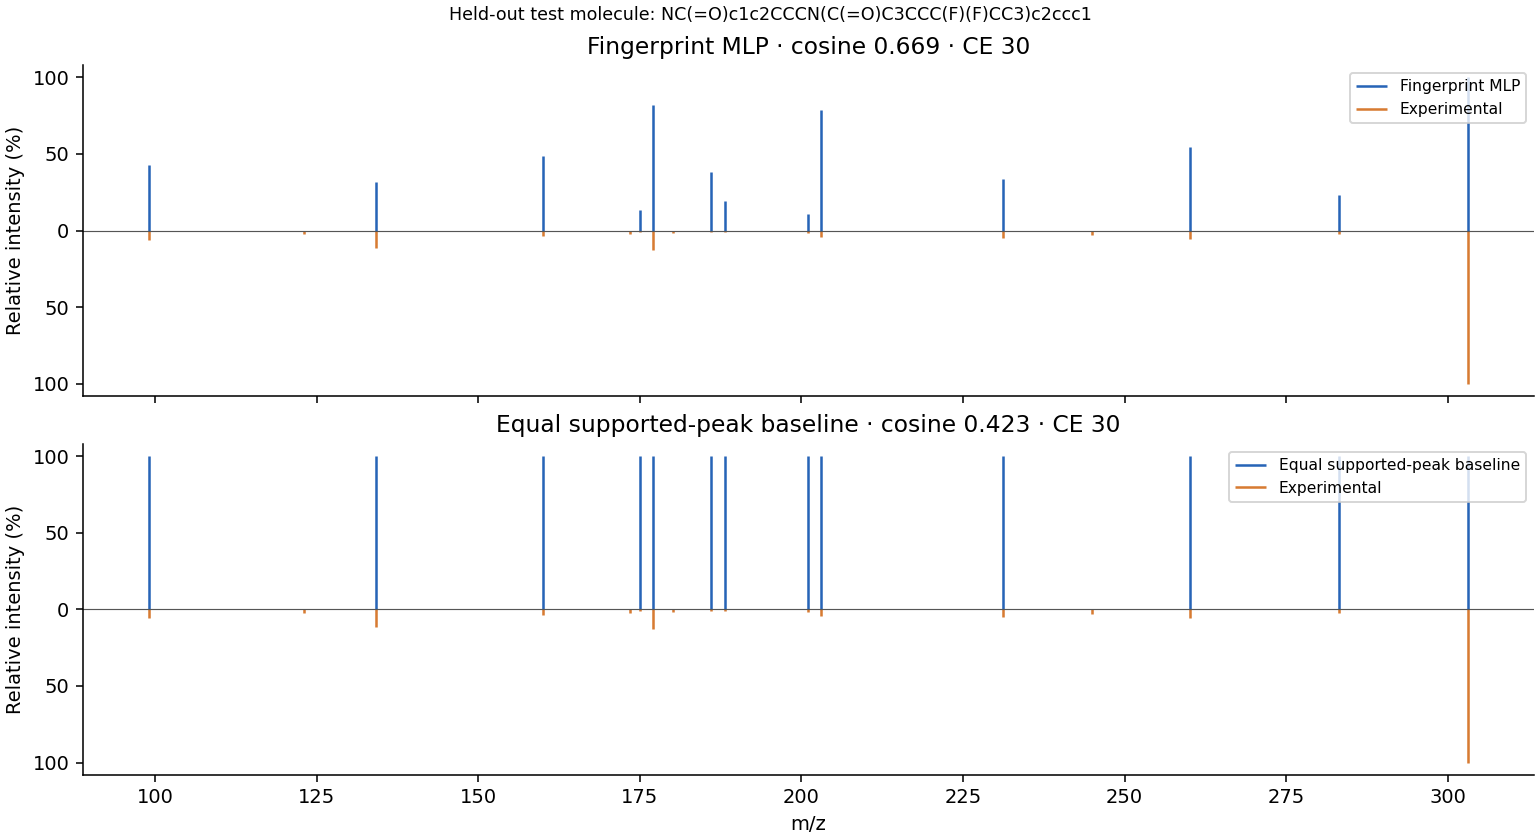

In [6]:
for example in results["plots"]:
    display(Image(filename=str(OUTPUT / example["file"])))

## Inference on one held-out example

`predict_spectrum(model, precursor_smiles, collision_energy, candidate_bags)` returns an `N × 2` array of m/z and base-peak-normalized intensity **in the supplied bag order**. It enforces nearest assignment and max aggregation; optional MS3 entries are ignored. Existing MAGMa bags can be reused directly.

The example reads only one test record. MAGMa receives a copy with zero intensity placeholders; experimental intensities enter only the final comparison plot. No full library or feature cache is loaded into the notebook.


In [7]:
# The descriptor-only baseline is available with CHECKPOINT = "descriptor_model.pt".
CHECKPOINT = "model.pt"
model = load_model(OUTPUT / CHECKPOINT)
with DATA.open("rb") as stream:
    stream.seek(results["plots"][0]["source_offset"])
    spectrum = Spectrum.from_record(json.loads(stream.readline()))

magma_input = Spectrum(spectrum.smiles, spectrum.precursor_mz, spectrum.ms_level,
                       np.column_stack((spectrum.mz, np.zeros(len(spectrum.mz)))),
                       spectrum.metadata.copy())
bags = get_candidate_bags(magma_input, spectra=[], peak_assignment="nearest")
predicted = predict_spectrum(model, spectrum.smiles,
                             spectrum.metadata["collision_energy"], bags)
assert np.array_equal(predicted[:, 0], spectrum.mz)
print(f"Predicted {np.count_nonzero(predicted[:, 1])} supported peaks of {len(predicted)} observed peaks")


Predicted 14 supported peaks of 20 observed peaks


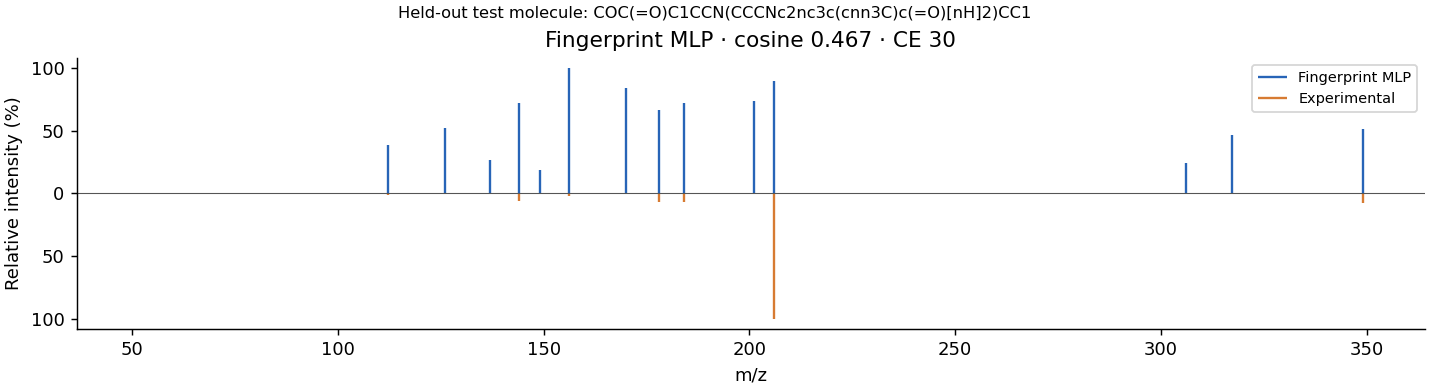

In [8]:
example = {"smiles": spectrum.smiles,
           "collision_energy": spectrum.metadata["collision_energy"],
           "mz": spectrum.mz, "target": spectrum.intensity}
figure = plot_comparison(example, predicted[:, 1])
# Export through the same helper without accumulating live pyplot figures.
from io import BytesIO
preview = BytesIO()
figure.savefig(preview, format="png", dpi=130)
display(Image(data=preview.getvalue()))

## Results and scope

Read the [updated result summary](results/experiment_2_v2/SUMMARY.md). That directory contains both selected checkpoints, fresh-cohort metrics, CE-response diagnostics, plots, the sample manifest, and a local feature cache.

Historical artifacts remain available: [original result summary](results/experiment_2/SUMMARY.md) and [original error analysis](results/experiment_2/ERROR_ANALYSIS.md). The original checkpoint is preserved for the comparisons above.

This is one bounded sample and one seed. A good spectrum score does not identify which latent fragment was correct. Observed peak locations are supplied to MAGMa, and unsupported peaks cannot be predicted. The experiment does not test unseen instruments, peak discovery, or prediction without experimental mass locations. CE20/CE60 sensitivity demonstrates a changing prediction, not correct energy dependence by itself.


## Why this revision was made

The [historical error analysis](results/experiment_2/ERROR_ANALYSIS.md) found that the original 300-molecule experiment had strong candidate support but weak learned intensities: its support ceiling was **0.975**, versus mean test cosine **0.488**. The model largely ignored collision energy, overfit 210 training molecules, and predicted diffuse intensity. Nearby centroids could also receive identical candidate sets.

The changes above directly address those observations. Fresh held-out comparisons, the descriptor-only control, effective peak counts, and fixed-support CE20/CE60 diagnostics measure whether they helped. The original report's numbers refer to its older cohort, not this revision's fresh test set.


The descriptor-only baseline is slightly stronger on both validation and test in this run. Both new models improve over the frozen original on the same fresh cohort. Predictions remain too diffuse: the fingerprint model averages 12.48 effective peaks versus 4.54 experimentally. See the [result summary](results/experiment_2_v2/SUMMARY.md) for scope and remaining limitations.